In [2]:
import tensorflow as tf

# Load the Fashion MNIST dataset
fmnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = fmnist.load_data()

# Normalize the pixel values
training_images = training_images / 255.0
test_images = test_images / 255.0

4431872/4422102 [==============================] - 0s 0us/step


In [ ]:
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.MaxPooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 800)               0         
                                                                 
 dense (Dense)               (None, 128)               1

In [ ]:
#visualizing the convolutions
print(test_labels[:100])

[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0 2 5 7 9 1 4 6 0 9 3 8 8 3 3 8 0 7
 5 7 9 6 1 3 7 6 7 2 1 2 2 4 4 5 8 2 2 8 4 8 0 7 7 8 5 1 1 2 3 9 8 7 0 2 6
 2 3 1 2 8 4 1 8 5 9 5 0 3 2 0 6 5 3 6 7 1 8 0 1 4 2]


[<KerasTensor: shape=(None, 26, 26, 32) dtype=float32 (created by layer 'conv2d')>, <KerasTensor: shape=(None, 13, 13, 32) dtype=float32 (created by layer 'max_pooling2d')>, <KerasTensor: shape=(None, 11, 11, 32) dtype=float32 (created by layer 'conv2d_1')>, <KerasTensor: shape=(None, 5, 5, 32) dtype=float32 (created by layer 'max_pooling2d_1')>, <KerasTensor: shape=(None, 800) dtype=float32 (created by layer 'flatten')>, <KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'dense')>, <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_1')>]


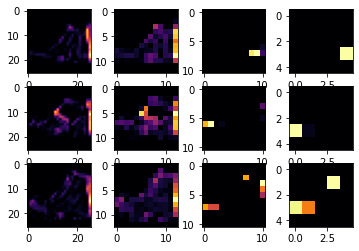

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras import models

f, axarr = plt.subplots(3,4)

FIRST_IMAGE=0
SECOND_IMAGE=23
THIRD_IMAGE=28
CONVOLUTION_NUMBER=1

layer_outputs = [layer.output for layer in model.layers]
print(layer_outputs)
activation_model = tf.keras.models.Model(inputs = model.input, outputs = layer_outputs)
for x in range(0,4):
    f1 = activation_model.predict(test_images[FIRST_IMAGE].reshape(1,28,28,1))[x]
    axarr[0,x].imshow(f1[0,:,:,CONVOLUTION_NUMBER], cmap = 'inferno')
    axarr[0,x].grid(False)

    f2 = activation_model.predict(test_images[SECOND_IMAGE].reshape(1,28,28,1))[x]
    axarr[1,x].imshow(f2[0,:,:,CONVOLUTION_NUMBER], cmap = 'inferno')
    axarr[1,x].grid(False)

    f3 = activation_model.predict(test_images[THIRD_IMAGE].reshape(1,28,28,1))[x]
    axarr[2,x].imshow(f3[0,:,:,CONVOLUTION_NUMBER], cmap = 'inferno')
    axarr[2,x].grid(False)


In [ ]:
#exercise 1 : reduce the convolutions from 32 x 32 to 24 x 24
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(24, (3,3), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.MaxPooling2D(2, 2),
     tf.keras.layers.Conv2D(24, (3,3), activation='relu'),
     tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 24)        240       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 24)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 24)        5208      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 24)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 600)               0         
                                                                 
 dense (Dense)               (None, 128)               7

In [ ]:
#exercise 2 : remove the 2nd convolution and max pooling layer 
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.MaxPooling2D(2, 2),
     #tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     #tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 13, 13, 32)       0         
 2D)                                                             
                                                                 
 flatten_2 (Flatten)         (None, 5408)              0         
                                                                 
 dense_4 (Dense)             (None, 128)               692352    
                                                                 
 dense_5 (Dense)             (None, 10)                1290      
                                                                 
Total params: 693,962
Trainable params: 693,962
Non-trainable params: 0
________________________________________________

In [ ]:
#exercise 3 : keep only the first convolutional layer
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     #tf.keras.layers.MaxPooling2D(2, 2),
     #tf.keras.layers.Conv2D(24, (3,3), activation='relu'),
     #tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 flatten_4 (Flatten)         (None, 21632)             0         
                                                                 
 dense_8 (Dense)             (None, 128)               2769024   
                                                                 
 dense_9 (Dense)             (None, 10)                1290      
                                                                 
Total params: 2,770,634
Trainable params: 2,770,634
Non-trainable params: 0
_________________________________________________________________

MODEL TRAINING:
Epoch 1/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.3788 - accuracy: 0.8651
Epoch 2/5
1875/1875 [==============================] - 5s 

In [ ]:
#exercise 4 : remove the pooling layers 
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     #tf.keras.layers.MaxPooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     #tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 conv2d_7 (Conv2D)           (None, 24, 24, 32)        9248      
                                                                 
 flatten_5 (Flatten)         (None, 18432)             0         
                                                                 
 dense_10 (Dense)            (None, 128)               2359424   
                                                                 
 dense_11 (Dense)            (None, 10)                1290      
                                                                 
Total params: 2,370,282
Trainable params: 2,370,282
Non-trainable params: 0
_________________________________________________________________

MODEL TRAINING:
Epoch 1/5
1875/1875 [======

In [ ]:
#exercise 5 : use average pooling
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.AveragePooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     tf.keras.layers.AveragePooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_11 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 average_pooling2d_2 (Averag  (None, 13, 13, 32)       0         
 ePooling2D)                                                     
                                                                 
 conv2d_12 (Conv2D)          (None, 11, 11, 32)        9248      
                                                                 
 average_pooling2d_3 (Averag  (None, 5, 5, 32)         0         
 ePooling2D)                                                     
                                                                 
 flatten_7 (Flatten)         (None, 800)               0         
                                                                 
 dense_14 (Dense)            (None, 128)              

In [3]:
#exercise 6 : use more convolutional layers 
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.AveragePooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     tf.keras.layers.AveragePooling2D(2,2), 
     tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     tf.keras.layers.AveragePooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 average_pooling2d (AverageP  (None, 13, 13, 32)       0         
 ooling2D)                                                       
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 32)        9248      
                                                                 
 average_pooling2d_1 (Averag  (None, 5, 5, 32)         0         
 ePooling2D)                                                     
                                                                 
 conv2d_2 (Conv2D)           (None, 3, 3, 32)          9248      
                                                                 
 average_pooling2d_2 (Averag  (None, 1, 1, 32)         0

In [5]:
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self,epoch,logs={}):
        if (logs.get('loss') <= 0.3) :
            print("\n reached loss less than 0.3 so terminating training !!! \n")
            self.model.stop_training = True

callbacks = myCallback()
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.MaxPooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
     tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5, callbacks=[callbacks])

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 13, 13, 32)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 11, 11, 32)        9248      
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten_2 (Flatten)         (None, 800)               0         
                                                                 
 dense_4 (Dense)             (None, 128)              

In [6]:
#exercise 7 : change convolution size
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (5,5), activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.MaxPooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (5,5), activation='relu'),
     tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_7 (Conv2D)           (None, 24, 24, 32)        832       
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 12, 12, 32)       0         
 2D)                                                             
                                                                 
 conv2d_8 (Conv2D)           (None, 8, 8, 32)          25632     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 4, 4, 32)         0         
 2D)                                                             
                                                                 
 flatten_3 (Flatten)         (None, 512)               0         
                                                                 
 dense_6 (Dense)             (None, 128)              

In [7]:
#experiment 8 : change stride
model = tf.keras.models.Sequential(
    [
     #Add convolutions and max pooling
     tf.keras.layers.Conv2D(32, (3,3), strides=2,activation='relu', input_shape=(28, 28, 1)),
     tf.keras.layers.MaxPooling2D(2, 2),
     tf.keras.layers.Conv2D(32, (3,3), strides=2,activation='relu'),
     tf.keras.layers.MaxPooling2D(2,2), 
     #Add layers as before 
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation=tf.nn.relu),
     tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ]
)

#Print the model summary
model.summary()

#Use same settings
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Train the model
print(f'\nMODEL TRAINING:')
model.fit(training_images,training_labels,epochs=5)

#Evaluate on the test set
print(f'\nMODEL EVALUATION')
test_loss = model.evaluate(test_images,test_labels)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_9 (Conv2D)           (None, 13, 13, 32)        320       
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 6, 6, 32)         0         
 2D)                                                             
                                                                 
 conv2d_10 (Conv2D)          (None, 2, 2, 32)          9248      
                                                                 
 max_pooling2d_7 (MaxPooling  (None, 1, 1, 32)         0         
 2D)                                                             
                                                                 
 flatten_4 (Flatten)         (None, 32)                0         
                                                                 
 dense_8 (Dense)             (None, 128)              

|Sl No|Experiment | No of params | Train error | Train accuracy | Test error | Test Accuracy | Diagnosis |
|---|---|---|---|---|---|---|---|
|0|Base (2 layers of 32X32 conv + maxpool) | 113386 | 0.2186 | 0.9186 | 0.2642 | 0.9019| default
|1| (32x32) replaced with (24x24) | 83666 | 0.238 | 0.9116 | 0.3022 | 0.8984 | slight increase in train - test error | 
|2| remove 2nd conv and maxpool layer | 693962 | 0.1575 | 0.9414 | 0.2457 | 0.9146 | more parameters leads to better train and test performance. however there is increase in variance |
|3| keep only 1st conv | 2770634 | 0.1158 | 0.9561 | 0.3089 | 0.9076 | improved test performance with increased variance |
|4| remove the pooling layers | 2370282 | 0.0805 | 0.97 | 0.3114 | 0.9122 | increased variance |
|5| use average pooling | 113386 | 0.2535 | 0.9070 | 0.2794 | 0.8980 | max pooling is better than average pooling |
|6| use addl conv + maxpool layer | 24330 | 0.3877 | 0.8586 | 0.3948 | 0.8587 | increased bias |
|7| change conv from (3 X 3) to (5 X 5) | 93418 | 0.2322 | 0.9135 | 0.2748 | 0.9072 | slightly decreased performance as compared to (3 X 3) conv |
|8| use stride of 2 | 15082 | 0.3686 | 0.8641 | 0.3917 | 0.8599 | increased bias due to lower number of parameters |